# Physical-metric calculation pipeline

**Analytical question:** Measure movement and physical effort.

**Stages in this notebook:** Smooth positions; velocity; acceleration; distance integration; intensity bands; efforts; crossing times; sample peaks.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

## Reading the code

Each statement performs one step. Names describe the values being calculated, and comments explain the purpose or units. A `for` loop repeats the indented steps for each player, frame or example. A function groups steps that we reuse later.

`pandas` tables hold the data. Square brackets select columns or rows; a condition such as `distance < 2` creates a True/False filter. `NumPy` arrays hold numbers for the calculations. `axis=0` refers to rows and `axis=1` to columns in a two-dimensional array. Shape comments explain additional dimensions where needed.

Run the worked calculations in order before using the final exploration section. The plotting and file-loading functions are included here so the notebook runs on its own.

Use `and` to combine individual True/False values. Use `&` to combine whole pandas columns of conditions. `np.hypot(dx, dy)` calculates distance from horizontal and vertical differences. `np.column_stack` joins columns, while `np.concatenate` joins existing arrays.

In [1]:
from pathlib import Path
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT_items_1 = []
for p in candidates:
    if (p / "data/1925299/1925299_match.json").exists():
        ROOT_items_1.append(p)
if len(ROOT_items_1) > 0:
    ROOT = ROOT_items_1[0]
else:
    ROOT = Path.cwd()
DATA_ROOT = ROOT / "data/1925299"


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None  # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None  # possession_index from available_possessions near the end
EVENT_ID = None  # actual supplied event_id from available_events, not row number
PLAYER_ID = None  # player_id (string or integer), from metadata
TEAM_ID = None  # team_id; None uses the initial possession team
DURATION_S = 6.0  # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3  # use 1 for every 10 Hz frame; 3 gives a faster preview
METRIC = "speed"  # speed, acceleration, distance, or sprints


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True, exist_ok=True)
    revision = "4340d274572876239c154c90bc507a9b3250a656"
    base = f"https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/"
    for suffix in ["match.json", "dynamic_events.csv", "phases_of_play.csv"]:
        name = "1925299_" + suffix
        target = destination / name
        if not target.exists():
            with urllib.request.urlopen(base + name, timeout=90) as response:
                target.write_bytes(response.read())
    name = "1925299_tracking_extrapolated.jsonl"
    target = destination / name
    if not target.exists():
        url = (
            base.replace(
                "raw.githubusercontent.com/", "media.githubusercontent.com/media/"
            )
            + name
        )
        temporary = destination / (name + ".partial")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open(
            "wb"
        ) as output:
            count = 0
            for line in response:
                if line.strip():
                    json.loads(line)
                    output.write(line)
                    count += 1
                if count >= 9000:
                    break
        temporary.replace(target)


def read_tracking(destination):
    """Load the sample and make one table row for each player in each frame."""
    dataset = skillcorner.load(
        meta_data=destination / "1925299_match.json",
        raw_data=destination / "1925299_tracking_extrapolated.jsonl",
        coordinates="skillcorner",
    )
    wide = dataset.to_df()
    metadata_file = destination / "1925299_match.json"
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))

    # Each line in the tracking file is one JSON record.
    raw_records = []
    tracking_file = destination / "1925299_tracking_extrapolated.jsonl"
    for line in tracking_file.read_text().splitlines():
        if line.strip():
            raw_records.append(json.loads(line))

    # Dictionaries let us look up a value using a frame or player identifier.
    player_possession = {}
    visibility = {}
    for record in raw_records:
        frame_number = record["frame"]
        possession = record.get("possession", {})
        (player_possession[frame_number]) = str(possession.get("player_id"))
        for player in record.get("player_data", []):
            player_id = str(player["player_id"])
            (visibility[frame_number, player_id]) = player.get("is_detected")

    player_tables = []
    for player in metadata["players"]:
        player_id = str(player["id"])
        x_column = player_id + "_x"
        y_column = player_id + "_y"
        if x_column not in wide.columns:
            continue
        columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "ball_owning_team_id",
            x_column,
            y_column,
        ]
        player_table = wide[columns].copy()
        player_table.columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "team_in_possession",
            "x",
            "y",
        ]
        (player_table["player_id"]) = player_id
        (player_table["team_id"]) = player["team_id"]
        (player_table["name"]) = player["short_name"]
        player_tables.append(player_table)

    tracking = pd.concat(player_tables, ignore_index=True)
    (tracking["seconds"]) = tracking["timestamp"].dt.total_seconds()
    (tracking["player_in_possession"]) = tracking["frame_id"].map(player_possession)
    detection_flags = []
    for row in tracking.itertuples():
        detection_flags.append(visibility.get((row.frame_id, row.player_id)))
    (tracking["is_detected"]) = detection_flags
    tracking = tracking.sort_values(["player_id", "period_id", "frame_id"])
    return dataset, wide, tracking, metadata, raw_records


def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5.5))
    ax.set_facecolor("#eef3ed")
    ax.add_patch(Rectangle((-52.5, -34), 105, 68, fill=False, color="#597063"))
    ax.plot([0, 0], [-34, 34], c="#597063")
    ax.add_patch(Circle((0, 0), 9.15, fill=False, color="#597063"))
    for x in [-52.5, 36]:
        ax.add_patch(Rectangle((x, -20.16), 16.5, 40.32, fill=False, color="#597063"))
    ax.set(
        xlim=(-55, 55), ylim=(-36, 36), aspect="equal", xlabel="x (m)", ylabel="y (m)"
    )
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset, wide, tracking, metadata, raw = read_tracking(DATA_ROOT)
events = pd.read_csv(DATA_ROOT / "1925299_dynamic_events.csv")
phases = pd.read_csv(DATA_ROOT / "1925299_phases_of_play.csv")
observed = tracking.dropna(subset=["x", "y"])
complete = observed.groupby(["period_id", "frame_id"]).size()
if FRAME_ID is not None:
    frame_id = int(FRAME_ID)
else:
    frame_id = int(complete[complete == 22].index[20][1])
snapshot = observed[observed.frame_id == frame_id].copy()
keepers = set()
for p in metadata["players"]:
    if "goalkeeper" in p["player_role"]["name"].lower():
        keepers.add(str(p["id"]))
role_labels = {}
for p in metadata["players"]:
    (role_labels[str(p["id"])]) = p["player_role"]["acronym"]
assert not tracking.duplicated(["period_id", "frame_id", "player_id"]).any()
display(
    tracking[["period_id", "frame_id", "player_id", "x", "y", "is_detected"]].head(3)
)
print("Real bounded sample. Diagnostic frame:", frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Select a continuous player segment

Inspect raw coordinates and timestamps before applying smoothing or derivatives.

,frame_id,seconds,x,y
70634,4637,462.7,-43.16,-2.23
70635,4638,462.8,-43.05,-2.24
70636,4639,462.9,-42.94,-2.26
70637,4640,463.0,-42.82,-2.27
70638,4641,463.1,-42.70,-2.30
70639,4642,463.2,-42.58,-2.32
70640,4643,463.3,-42.45,-2.36
70641,4644,463.4,-42.31,-2.40
70642,4645,463.5,-42.17,-2.46
70643,4646,463.6,-42.02,-2.52


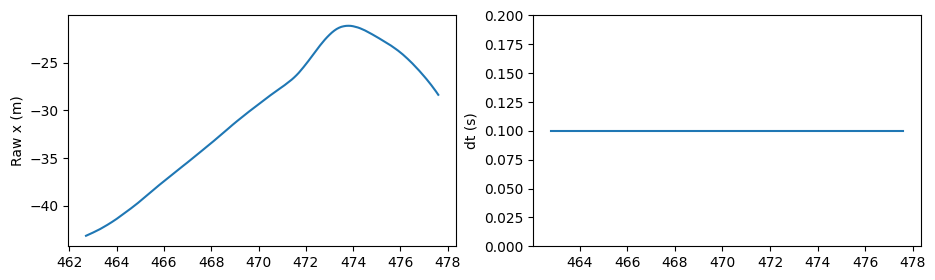

In [5]:
g = (
    tracking[tracking.player_id == snapshot.player_id.iloc[0]]
    .dropna(subset=["x", "y"])
    .sort_values(["period_id", "frame_id"])
)
breaks = ((g.frame_id.diff() != 1) | (g.period_id != g.period_id.shift())).cumsum()
segment_items_1 = []
for _, s in g.groupby(breaks):
    segment_items_1.append(s)
segment = max(segment_items_1, key=len).head(150)
t = segment.seconds.to_numpy()
xy = segment[["x", "y"]].to_numpy()
display(segment[["frame_id", "seconds", "x", "y"]].head(10))
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].plot(t, xy[:, 0])
axs[0].set_ylabel("Raw x (m)")
axs[1].plot(t, np.diff(t, prepend=np.nan))
axs[1].set_ylabel("dt (s)")
axs[1].set_ylim(0, 0.2)
axs[1].ticklabel_format(axis="y", style="plain", useOffset=False)
plt.show()


## 5. Smooth coordinates, then differentiate

Expose the two operations and compare their outputs on the same segment.

,time,raw_x,smooth_x,raw_vx,smooth_vx
0,462.7,-43.16,-43.096126,1.10,0.711806
1,462.8,-43.05,-43.024945,1.10,0.840018
2,462.9,-42.94,-42.928122,1.15,1.043850
3,463.0,-42.82,-42.816175,1.20,1.157233
4,463.1,-42.70,-42.696676,1.20,1.221142
5,463.2,-42.58,-42.571947,1.25,1.275450
6,463.3,-42.45,-42.441586,1.35,1.333840
7,463.4,-42.31,-42.305179,1.40,1.392738
8,463.5,-42.17,-42.163038,1.45,1.447872
9,463.6,-42.02,-42.015605,1.50,1.499949


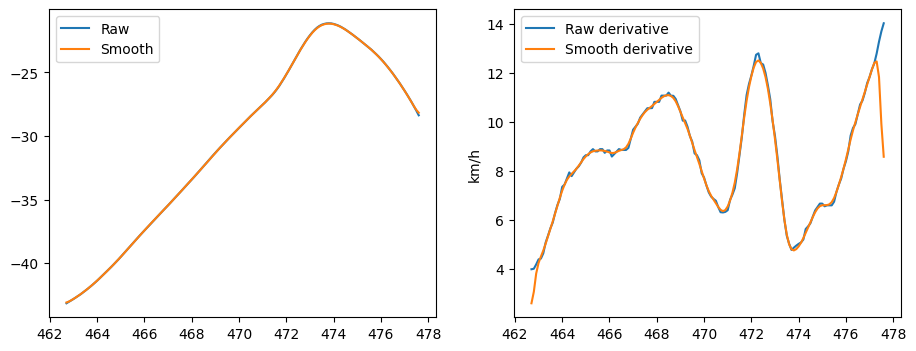

In [6]:
from scipy.ndimage import gaussian_filter1d


def smooth_coordinates(xy, sigma=1.5):
    return gaussian_filter1d(np.asarray(xy), sigma=sigma, axis=0, mode="nearest")


def differentiate_coordinates(xy, time):
    return np.gradient(np.asarray(xy), np.asarray(time), axis=0)


smoothed = smooth_coordinates(xy)
raw_velocity = differentiate_coordinates(xy, t)
smooth_velocity = differentiate_coordinates(smoothed, t)
display(
    pd.DataFrame(
        {
            "time": t,
            "raw_x": xy[:, 0],
            "smooth_x": smoothed[:, 0],
            "raw_vx": raw_velocity[:, 0],
            "smooth_vx": smooth_velocity[:, 0],
        }
    ).head(10)
)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(t, xy[:, 0], label="Raw")
axs[0].plot(t, smoothed[:, 0], label="Smooth")
axs[0].legend()
axs[1].plot(t, np.linalg.norm(raw_velocity, axis=1) * 3.6, label="Raw derivative")
axs[1].plot(t, np.linalg.norm(smooth_velocity, axis=1) * 3.6, label="Smooth derivative")
axs[1].set_ylabel("km/h")
axs[1].legend()
plt.show()


## 6. Apply the inspected calculation to valid segments

Build a reusable pipeline with explicit gap, period and filter-boundary handling. Scalar acceleration is the derivative of scalar speed.

In [7]:
def derive_motion(tracking):
    motion = tracking.copy()
    (motion[["vx", "vy", "speed_kmh", "accel"]]) = np.nan
    for _, player_frames in motion.groupby(["player_id", "period_id"]):
        valid = player_frames[["x", "y"]].notna().all(axis=1)
        split = (
            ~valid
            | ~valid.shift(fill_value=False)
            | (player_frames.frame_id.diff() != 1)
            | (player_frames.seconds.diff() <= 0)
        ).cumsum()
        for _, continuous_frames in player_frames[valid].groupby(split[valid]):
            if len(continuous_frames) < 20:
                continue
            time_seconds = continuous_frames.seconds.to_numpy()
            smoothed_positions = smooth_coordinates(
                continuous_frames[["x", "y"]].to_numpy()
            )
            velocity = differentiate_coordinates(smoothed_positions, time_seconds)
            speed = np.linalg.norm(velocity, axis=1)
            acceleration = np.gradient(speed, time_seconds)
            (velocity[:5]) = np.nan
            (velocity[-5:]) = np.nan
            (speed[:5]) = np.nan
            (speed[-5:]) = np.nan
            (acceleration[:6]) = np.nan
            (acceleration[-6:]) = np.nan
            (motion.loc[continuous_frames.index, ["vx", "vy"]]) = velocity
            (motion.loc[continuous_frames.index, "speed_kmh"]) = speed * 3.6
            (motion.loc[continuous_frames.index, "accel"]) = acceleration
    return motion


motion = derive_motion(tracking)
display(
    motion[["player_id", "frame_id", "vx", "vy", "speed_kmh", "accel"]].dropna().head()
)
player = motion.groupby("player_id").speed_kmh.max().idxmax()


,player_id,frame_id,vx,vy,speed_kmh,accel
67689,11897,46,-0.247765,0.174801,1.091594,0.606738
67690,11897,47,-0.290122,0.221082,1.313129,0.610326
67691,11897,48,-0.324011,0.275472,1.531029,0.607658
67692,11897,49,-0.350501,0.337086,1.750643,0.646995
67693,11897,50,-0.378850,0.405152,1.996865,0.738426


## 7. Inspect interval distance contributions

Use the same interval helper for both the diagnostic and the later summary. Coverage remains explicit.

,frame_id,dt,mean_kmh,band,metres,cumulative_m
123066,46,0.1,1.095098,below HSR,0.030419,0.030419
123067,47,0.1,1.020167,below HSR,0.028338,0.058757
123068,48,0.1,0.872024,below HSR,0.024223,0.082980
123069,49,0.1,0.631472,below HSR,0.017541,0.100521
123070,50,0.1,0.296680,below HSR,0.008241,0.108762
123071,51,0.1,0.262038,below HSR,0.007279,0.116041
123072,52,0.1,0.732313,below HSR,0.020342,0.136383
123073,53,0.1,1.416043,below HSR,0.039335,0.175718
123074,54,0.1,2.195339,below HSR,0.060982,0.236699
123075,55,0.1,3.057082,below HSR,0.084919,0.321618


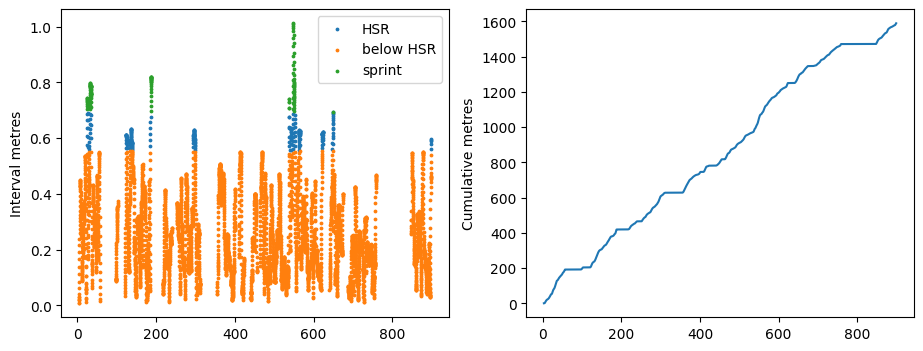

In [8]:
def interval_workload(player_frames):
    result = player_frames.sort_values(["period_id", "frame_id"]).copy()
    (result["dt"]) = result.seconds.diff()
    (result["mean_kmh"]) = (result.speed_kmh + result.speed_kmh.shift()) / 2
    valid = (
        (result.period_id == result.period_id.shift())
        & (result.frame_id.diff() == 1)
        & (result.dt > 0)
        & result.speed_kmh.notna()
        & result.speed_kmh.shift().notna()
    )
    (result["metres"]) = (result.mean_kmh / 3.6 * result.dt).where(valid)
    (result["cumulative_m"]) = result.metres.fillna(0).cumsum()
    (result["band"]) = np.select(
        [result.mean_kmh >= 25, result.mean_kmh >= 20],
        ["sprint", "HSR"],
        default="below HSR",
    )
    return result


intervals = interval_workload(motion[motion.player_id == player])
display(
    intervals[["frame_id", "dt", "mean_kmh", "band", "metres", "cumulative_m"]]
    .dropna()
    .head(12)
)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for band, g in intervals.groupby("band"):
    axs[0].scatter(g.seconds, g.metres, s=3, label=band)
axs[0].legend()
axs[0].set_ylabel("Interval metres")
axs[1].plot(intervals.seconds, intervals.cumulative_m)
axs[1].set_ylabel("Cumulative metres")
plt.show()


## 8. Group sprint efforts

An effort is a run of valid consecutive samples above the chosen threshold for at least the chosen duration. Signed acceleration remains a separate quantity.

,start_s,duration_s,peak_kmh
0,24.5,1.5,26.750991
1,31.1,3.9,28.732876
2,185.6,2.2,29.550376
3,547.1,4.1,36.498076


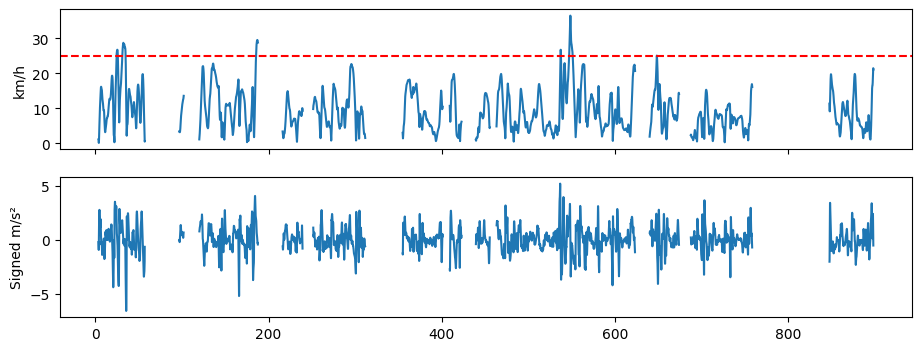

In [9]:
def sprint_efforts(player_frames, threshold=25, min_s=1):
    player_frames = player_frames.sort_values(["period_id", "frame_id"])
    active = player_frames.speed_kmh >= threshold
    segment = (
        (active != active.shift(fill_value=False))
        | (player_frames.frame_id.diff() != 1)
        | (player_frames.period_id != player_frames.period_id.shift())
    ).cumsum()
    rows = []
    for _, effort_frames in player_frames[active].groupby(segment[active]):
        duration = effort_frames.seconds.iloc[-1] - effort_frames.seconds.iloc[0] + 0.1
        if duration >= min_s:
            rows.append(
                {
                    "start_s": effort_frames.seconds.iloc[0],
                    "duration_s": duration,
                    "peak_kmh": effort_frames.speed_kmh.max(),
                }
            )
    return pd.DataFrame(rows, columns=["start_s", "duration_s", "peak_kmh"])


(display(sprint_efforts(motion[motion.player_id == player])))
g = motion[motion.player_id == player]
fig, axs = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
axs[0].plot(g.seconds, g.speed_kmh)
axs[0].axhline(25, c="red", ls="--")
axs[0].set_ylabel("km/h")
axs[1].plot(g.seconds, g.accel)
axs[1].set_ylabel("Signed m/s²")
plt.show()


## 9. Compare scalar and vector acceleration

Differentiate velocity components within a continuous valid segment before comparing vector magnitude with the signed speed derivative.

,time,scalar_accel,vector_magnitude
0,463.3,1.346041,1.414835
1,463.4,1.440941,1.473997
2,463.5,1.555566,1.602213
3,463.6,1.657018,1.738788
4,463.7,1.719011,1.841087
5,463.8,1.717012,1.863482
6,463.9,1.670306,1.832658
7,464.0,1.652764,1.831966
8,464.1,1.699233,1.881922
9,464.2,1.749248,1.909103


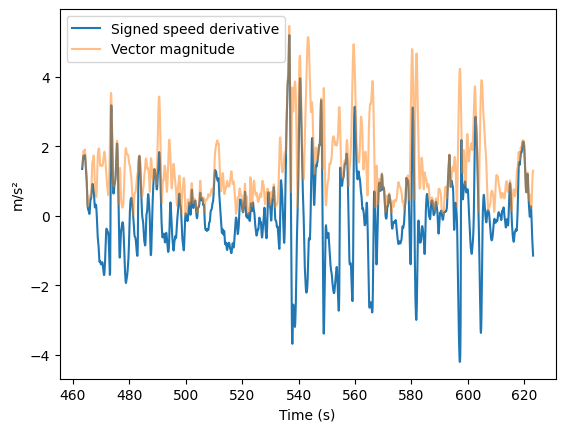

In [10]:
def acceleration_components(g):
    g = g.sort_values("frame_id").copy()
    time = g.seconds.to_numpy()
    v = g[["vx", "vy"]].to_numpy()
    vector = np.gradient(v, time, axis=0)
    magnitude = np.linalg.norm(vector, axis=1)
    return pd.DataFrame(
        {
            "time": time,
            "scalar_accel": g.accel.to_numpy(),
            "vector_magnitude": magnitude,
        }
    )


g = (
    motion[motion.player_id == player]
    .dropna(subset=["vx", "vy", "accel"])
    .sort_values(["period_id", "frame_id"])
)
breaks = ((g.frame_id.diff() != 1) | (g.period_id != g.period_id.shift())).cumsum()
g_items_1 = []
for _, s in g.groupby(breaks):
    g_items_1.append(s)
g = max(g_items_1, key=len)
diagnostic = acceleration_components(g)
display(diagnostic.head(10))
plt.plot(diagnostic.time, diagnostic.scalar_accel, label="Signed speed derivative")
plt.plot(
    diagnostic.time, diagnostic.vector_magnitude, label="Vector magnitude", alpha=0.5
)
plt.xlabel("Time (s)")
plt.ylabel("m/s²")
plt.legend()
plt.show()


## 10. Inspect threshold crossing and peak quality

Show crossing interpolation on a labeled synthetic speed trace before interpreting real sample maxima.

Synthetic 9 to 20 km/h: 0.8571428571428572 s
Synthetic 9 to 25 km/h: 1.25 s


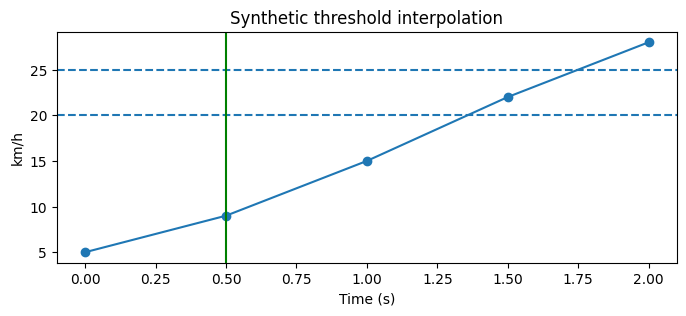

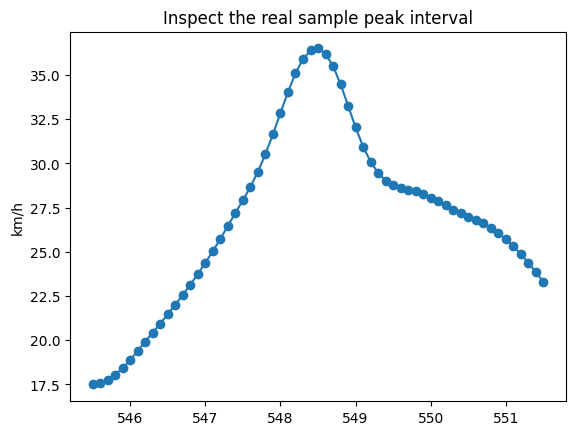

In [11]:
def crossing_time(t, v, threshold):
    hits = np.flatnonzero((v[:-1] < threshold) & (v[1:] >= threshold))
    if not len(hits):
        return np.nan
    i = hits[0]
    return t[i] + (threshold - v[i]) / (v[i + 1] - v[i]) * (t[i + 1] - t[i])


def inspect_peak(g):
    peak = g.loc[g.speed_kmh.idxmax()]
    window = g[
        g.frame_id.between(peak.frame_id - 30, peak.frame_id + 30)
        & (g.period_id == peak.period_id)
    ]
    return peak, window


time = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
speed = np.array([5.0, 9.0, 15.0, 22.0, 28.0])
start = crossing_time(time, speed, 9)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(time, speed, "o-")
for target in [20, 25]:
    end = crossing_time(time, speed, target)
    ax.axhline(target, ls="--")
    print("Synthetic 9 to", target, "km/h:", end - start, "s")
ax.axvline(start, c="green")
ax.set(xlabel="Time (s)", ylabel="km/h", title="Synthetic threshold interpolation")
plt.show()
peak, window = inspect_peak(motion[motion.player_id == player])
plt.plot(window.seconds, window.speed_kmh, "o-")
plt.title("Inspect the real sample peak interval")
plt.ylabel("km/h")
plt.show()
assert np.isclose(crossing_time(np.array([0, 1]), np.array([0, 20]), 9), 0.45)


## 11. Apply the inspected crossing helper to the sample

Find crossings within continuous rising-speed episodes. These remain illustrative crossings, not production-qualified SkillCorner explosive efforts.

In [12]:
crossings = []
for pid, g in motion.groupby("player_id"):
    g = g.sort_values(["period_id", "frame_id"])
    rising = (g.accel > 0) & g.speed_kmh.notna()
    split = (
        (rising != rising.shift(fill_value=False))
        | (g.frame_id.diff() != 1)
        | (g.period_id != g.period_id.shift())
    ).cumsum()
    for _, s in g[rising].groupby(split[rising]):
        if len(s) < 3:
            continue
        time = s.seconds.to_numpy()
        speed = s.speed_kmh.to_numpy()
        t9 = crossing_time(time, speed, 9)
        for target in [20, 25]:
            end = crossing_time(time, speed, target)
            if np.isfinite(t9 + end) and end > t9:
                crossings.append(
                    dict(player_id=pid, target_kmh=target, seconds=end - t9)
                )
display(pd.DataFrame(crossings, columns=["player_id", "target_kmh", "seconds"]))


,player_id,target_kmh,seconds
0,11897,20,1.863908
1,11897,20,1.233406
2,11897,20,1.087799
3,11897,20,1.199481
4,287934,20,1.642657
...,...,...,...
128,966114,20,2.856672
129,966114,20,2.213111
130,966114,20,1.427866
131,966114,20,1.517371


## 12. Final output: sample workload summary

Aggregate the interval contributions only after inspecting their construction. Report valid exposure alongside every partial-sample total.

,player_id,valid_s,coverage,distance_m,HSR_m,sprint_m,effort_count,sample_peak_kmh
15,795530,599.0,0.973509,1827.779733,127.104950,5.918825,0,27.568458
20,966112,600.1,0.975297,1782.537938,112.206502,0.000000,0,24.897186
1,287934,599.1,0.973671,1734.763138,133.898882,68.533104,3,28.348777
12,560986,598.4,0.972534,1673.156061,194.571831,59.046084,3,29.551199
7,51694,596.7,0.969771,1663.598835,89.350435,8.536913,1,26.061642
13,560987,600.3,0.975622,1662.790754,166.090654,22.804554,2,29.110785
9,560983,601.5,0.977572,1589.803595,148.280257,95.723360,4,36.498076
8,560882,596.4,0.969283,1589.280732,99.438639,19.340130,2,26.348442
17,797298,599.1,0.973671,1578.731245,149.828188,31.745373,2,28.210902
4,51002,601.5,0.977572,1568.436447,164.024403,0.000000,0,25.000118


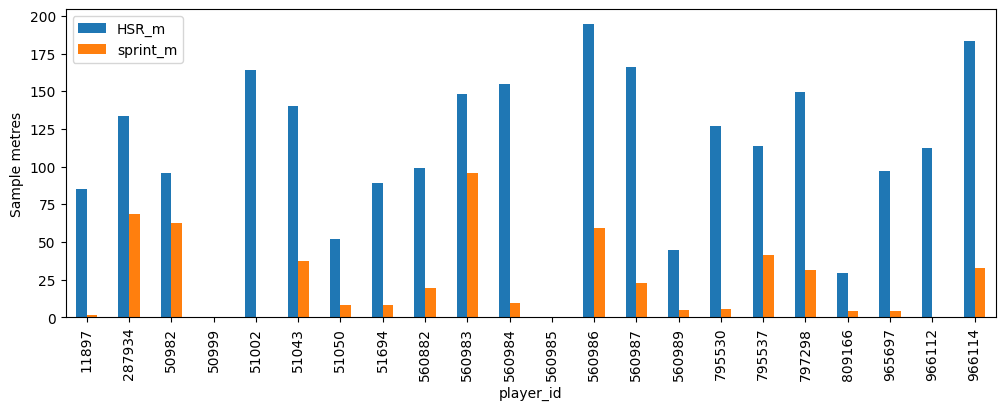

In [13]:
rows = []
for pid, g in motion.groupby("player_id"):
    intervals = interval_workload(g)
    valid = intervals.metres.notna()
    (
        rows.append(
            dict(
                player_id=pid,
                valid_s=intervals.dt.where(valid).sum(),
                coverage=valid.mean(),
                distance_m=intervals.metres.sum(),
                HSR_m=intervals.metres.where(intervals.band == "HSR").sum(),
                sprint_m=intervals.metres.where(intervals.band == "sprint").sum(),
                effort_count=len(sprint_efforts(g)),
                sample_peak_kmh=g.speed_kmh.max(),
            )
        )
    )
summary = pd.DataFrame(rows)
display(summary.sort_values("distance_m", ascending=False))
summary.set_index("player_id")[["HSR_m", "sprint_m"]].plot.bar(figsize=(12, 4))
plt.ylabel("Sample metres")
plt.show()


## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


Recomputed overlays on 20 real frames; first/last: (1, 245) (1, 302)


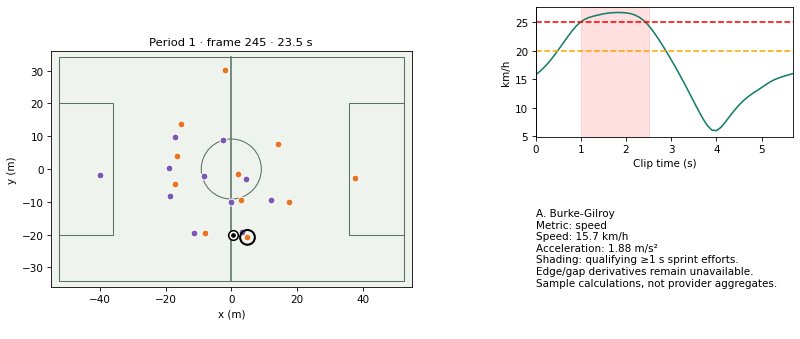

In [14]:
method_name = "physical"
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

players_by_id = {}
for player in metadata["players"]:
    (players_by_id[str(player["id"])]) = player
home_team_id = int(metadata["home_team"]["id"])
away_team_id = int(metadata["away_team"]["id"])
tracking_records = list(raw)
if method_name == "graph_epv":
    unique_records_by_key = {}
    for record in raw + goal_sequence:
        if record.get("period") is not None:
            (unique_records_by_key[int(record["period"]), int(record["frame"])]) = (
                record
            )
    tracking_records = list(unique_records_by_key.values())
source_frames = {}
for record in tracking_records:
    if record.get("period") is not None:
        (source_frames[int(record["period"]), int(record["frame"])]) = record
frames_by_key = {}
for frame_key, record in source_frames.items():
    position_flags = []
    for player in record["player_data"]:
        position_flags.append(
            player.get("x") is not None and player.get("y") is not None
        )
    if (
        frame_key[0] == PERIOD
        and len(record.get("player_data", [])) == 22
        and all(position_flags)
        and (record.get("ball_data", {}).get("x") is not None)
        and (record["ball_data"].get("y") is not None)
        and (record.get("timestamp") is not None)
    ):
        (frames_by_key[frame_key]) = record
assert frames_by_key, "No complete frames for PERIOD in the cached source."


def tracking_time(record):
    return pd.to_timedelta(record["timestamp"]).total_seconds()


def possession_team(record):
    """Translate the source's team label into the corresponding team identifier."""
    group = record.get("possession", {}).get("group")
    if group == "home team":
        return home_team_id
    if group == "away team":
        return away_team_id
    return None


def attack_direction(team, period):
    """Return -1 for attacks to the left and +1 for attacks to the right."""
    home_attacks_left = metadata["home_team_side"][period - 1] == "right_to_left"
    if team == home_team_id:
        attacks_left = home_attacks_left
    else:
        attacks_left = not home_attacks_left
    if attacks_left:
        return -1
    return 1


def players_at_frame(frame_key):
    """Make a player table and estimate velocity using the immediately previous frame."""
    record = frames_by_key[frame_key]
    period, frame_number = frame_key
    previous_record = source_frames.get((period, frame_number - 1))
    previous_players = {}
    elapsed_seconds = np.nan
    if previous_record is not None:
        for player in previous_record.get("player_data", []):
            (previous_players[str(player["player_id"])]) = player
        if previous_record.get("timestamp"):
            elapsed_seconds = tracking_time(record) - tracking_time(previous_record)

    player_rows = []
    for player in record["player_data"]:
        player_id = str(player["player_id"])
        previous_player = previous_players.get(player_id, {})
        velocity = np.array([np.nan, np.nan])
        valid_time = 0.05 <= elapsed_seconds <= 0.15
        has_previous_x = previous_player.get("x") is not None
        has_previous_y = previous_player.get("y") is not None
        if valid_time and has_previous_x and has_previous_y:
            current_position = np.array([player["x"], player["y"]])
            previous_position = np.array([previous_player["x"], previous_player["y"]])
            velocity = (current_position - previous_position) / elapsed_seconds
        player_rows.append(
            {
                "player_id": player_id,
                "team_id": int(players_by_id[player_id]["team_id"]),
                "x": player["x"],
                "y": player["y"],
                "vx": velocity[0],
                "vy": velocity[1],
                "is_detected": player.get("is_detected"),
            }
        )
    return pd.DataFrame(player_rows)


def draw_tracking_frame(axis, frame_key):
    tracking_record = frames_by_key[frame_key]
    player_table = players_at_frame(frame_key)
    pitch(axis)
    for team_id, color in [(home_team_id, "#e87524"), (away_team_id, "#7959b5")]:
        team_players = player_table[player_table.team_id == team_id]
        axis.scatter(
            team_players.x, team_players.y, c=color, edgecolors="white", s=44, zorder=5
        )
    ball_position = np.array(
        [tracking_record["ball_data"]["x"], tracking_record["ball_data"]["y"]]
    )
    axis.scatter(*ball_position, s=85, c="white", edgecolors="black", lw=1.5, zorder=10)
    axis.scatter(*ball_position, s=12, c="black", zorder=11)
    axis.set_title(
        f"Period {frame_key[0]} · frame {frame_key[1]} · {tracking_time(tracking_record):.1f} s",
        fontsize=11,
    )
    return player_table, ball_position, tracking_record


# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog = []
previous = None
group = None
for frame_key in sorted(frames_by_key):
    record = frames_by_key[frame_key]
    current_possession_team = possession_team(record)
    continuous = (
        previous is not None
        and frame_key[1] == previous[1] + 1
        and 0 < tracking_time(record) - tracking_time(frames_by_key[previous]) <= 0.15
    )
    if not continuous or current_possession_team != group:
        example_catalog.append(
            dict(
                possession_index=len(example_catalog),
                period=frame_key[0],
                start_frame=frame_key[1],
                end_frame=frame_key[1],
                team_id=current_possession_team,
            )
        )
    else:
        (example_catalog[-1]["end_frame"]) = frame_key[1]
    previous = frame_key
    group = current_possession_team
available_possessions = pd.DataFrame(example_catalog)
(available_possessions["duration_s"]) = (
    available_possessions.end_frame - available_possessions.start_frame + 1
) / 10
if "events" in globals():
    available_events_items_1 = []
    for k in frames_by_key:
        available_events_items_1.append(k[1])
    available_events = events[
        (events.period == PERIOD) & events.frame_start.isin(available_events_items_1)
    ].copy()
else:
    available_events = pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):
    display(
        available_events[["event_id", "event_type", "frame_start", "frame_end"]].head(
            10
        )
    )

clip_start_frame = None
clip_stop_frame = None
example_action = None
if method_name == "formation":
    available_windows = timeline[timeline.period == PERIOD].copy()
    display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):
        raise ValueError(
            "FORMATION_WINDOW must be a qualifying window in available_windows."
        )
    example_window_data = team_data[
        (team_data.period_id == PERIOD)
        & (team_data.window == FORMATION_WINDOW)
        & (team_data.team_in_possession == 871)
    ]
    example_med = example_window_data.groupby("player_id")[["cx", "cy"]].median()
    example_points = -example_med.to_numpy()
    example_fits = []
    for name, t in templates.items():
        cost = ((example_points[:, None] - t[None]) ** 2).sum(2)
        rr, cc = linear_sum_assignment(cost)
        example_fits.append((name, float(np.sqrt(cost[rr, cc].mean())), cc))

    def assignment_error(fit):
        return fit[1]

    example_fits.sort(key=assignment_error)
    example_best = example_fits[0]
    candidates = []
    for k in frames_by_key:
        if (
            FORMATION_WINDOW * 30
            <= tracking_time(frames_by_key[k])
            < (FORMATION_WINDOW + 1) * 30
        ):
            candidates.append(k[1])
    assert candidates, "Selected formation window has no complete animation frames."
    clip_start_frame = min(candidates)
    clip_stop_frame = max(candidates)
elif method_name == "events":
    display(passes.reset_index(names="pass_index").head(12))
    if len(passes):
        assert 0 <= PASS_INDEX < len(passes), "PASS_INDEX is a row number in passes."
        example_action = passes.iloc[PASS_INDEX]
        clip_start_frame = max(int(example_action.release) - 8, 0)
        clip_stop_frame = int(example_action.reception) + 12
elif method_name == "xt":
    example_actions_items_1 = []
    for k in frames_by_key:
        example_actions_items_1.append(k[1])
    example_actions = (
        events[
            (events.event_type == "player_possession")
            & (events.end_type == "pass")
            & (events.pass_outcome == "successful")
            & (events.period == PERIOD)
            & events.frame_end.isin(example_actions_items_1)
        ]
        .dropna(
            subset=[
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        )
        .copy()
    )
    display(
        example_actions[
            [
                "event_id",
                "frame_end",
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        ].head(12)
    )
    assert len(example_actions), "No completed actions with endpoint coverage."
    if EVENT_ID is None:
        example_action = example_actions.iloc[0]
    else:
        example_action = example_actions[example_actions.event_id == EVENT_ID].iloc[0]
    clip_start_frame = int(example_action.frame_end) - 5
elif method_name == "graph_epv" and SEQUENCE == "goal":
    clip_start_frame = int(goal_sequence[0]["frame"])
    clip_stop_frame = int(goal_sequence[-1]["frame"])
elif method_name == "graph_epv" and SEQUENCE == "non_goal":
    clip_start_frame = int(non_goal_sequence[0]["frame"])
    clip_stop_frame = int(non_goal_sequence[-1]["frame"])

if EVENT_ID is not None and method_name != "xt":
    chosen = available_events[available_events.event_id == EVENT_ID]
    assert (
        len(chosen) == 1
    ), "Choose EVENT_ID from available_events.event_id, not a row number."
    clip_start_frame = int(chosen.frame_start.iloc[0])
    clip_stop_frame = int(chosen.frame_end.iloc[0]) + 10
if POSSESSION_INDEX is not None:
    chosen = available_possessions[
        available_possessions.possession_index == POSSESSION_INDEX
    ]
    assert len(chosen) == 1, "Choose POSSESSION_INDEX from available_possessions."
    clip_start_frame = int(chosen.start_frame.iloc[0])
    clip_stop_frame = int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame = int(FRAME_ID)
    clip_stop_frame = None
if (
    clip_start_frame is None
    and FRAME_ID is None
    and POSSESSION_INDEX is None
    and EVENT_ID is None
):
    if PLAYER_ID is not None:
        initial_player = str(PLAYER_ID)
    else:
        initial_player = str(
            summary.sort_values("sprint_m", ascending=False).player_id.iloc[0]
        )
    example_efforts = sprint_efforts(motion[motion.player_id == initial_player])
    if len(example_efforts):
        start_seconds = max(0, float(example_efforts.start_s.iloc[0]) - 1)
        starts = []
        for k in sorted(frames_by_key):
            if tracking_time(frames_by_key[k]) >= start_seconds:
                starts.append(k[1])
        if starts:
            clip_start_frame = starts[0]
if clip_start_frame is None:
    clip_start_frame = int(frame_id)
if (PERIOD, clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible = []
    for k in sorted(frames_by_key):
        if k[1] >= clip_start_frame and (
            clip_stop_frame is None or k[1] <= clip_stop_frame
        ):
            possible.append(k[1])
    assert possible, "No covered frame for this selection."
    clip_start_frame = possible[0]
clip_keys = []
for f in range(clip_start_frame, clip_start_frame + max(2, int(DURATION_S * 10))):
    frame_key = (PERIOD, f)
    if frame_key not in frames_by_key or (
        clip_stop_frame is not None and f > clip_stop_frame
    ):
        break
    if (
        clip_keys
        and not 0
        < tracking_time(frames_by_key[frame_key])
        - tracking_time(frames_by_key[clip_keys[-1]])
        <= 0.15
    ):
        break
    clip_keys.append(frame_key)
assert (
    len(clip_keys) >= 2
), "Selection ends at a coverage boundary; choose another covered start."
assert FRAME_STRIDE >= 1
clip_keys = clip_keys[::FRAME_STRIDE]
assert len(clip_keys) >= 2, "Reduce FRAME_STRIDE or increase clip duration."
if TEAM_ID is not None:
    selected_team = TEAM_ID
else:
    selected_team = possession_team(frames_by_key[clip_keys[0]]) or home_team_id
if PLAYER_ID is not None:
    focus_player_id = str(PLAYER_ID)
else:
    focus_player_id_items_1 = []
    for player in metadata["players"]:
        if int(player["team_id"]) == selected_team:
            focus_player_id_items_1.append(player["id"])
    if len(focus_player_id_items_1) > 0:
        focus_player_id_first_match_2 = focus_player_id_items_1[0]
    else:
        raise ValueError(
            "No matching item was found. Check the available data or your selection."
        )
    focus_player_id = str(focus_player_id_first_match_2)
if method_name == "physical" and PLAYER_ID is None:
    focus_player_id = str(
        summary.sort_values("sprint_m", ascending=False).player_id.iloc[0]
    )
example_origin = tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys = clip_keys

example_work = interval_workload(motion[motion.player_id == focus_player_id])
assert len(example_work), "Choose PLAYER_ID from summary.player_id."
example_efforts = sprint_efforts(motion[motion.player_id == focus_player_id])


def draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis):
    for plot_axis in [pitch_axis, detail_axis, summary_axis]:
        plot_axis.clear()
    player_table, ball_position, tracking_record = draw_tracking_frame(
        pitch_axis, frame_key
    )
    clip_seconds = tracking_time(tracking_record) - example_origin
    summary_axis.axis("off")
    player_segment = example_work[
        (example_work.period_id == PERIOD)
        & example_work.frame_id.between(clip_keys[0][1], clip_keys[-1][1])
    ]
    current_measurements = player_segment[player_segment.frame_id == frame_key[1]]
    selected_player = player_table[player_table.player_id == focus_player_id]
    pitch_axis.scatter(
        selected_player.x,
        selected_player.y,
        s=200,
        facecolors="none",
        edgecolors="black",
        lw=2,
        zorder=9,
    )
    metric_column = {
        "speed": "speed_kmh",
        "acceleration": "accel",
        "distance": "cumulative_m",
        "sprints": "speed_kmh",
    }[METRIC]
    detail_axis.plot(
        player_segment.seconds - example_origin,
        player_segment[metric_column],
        c="#147d68",
    )
    detail_axis.axvline(clip_seconds, c="black")
    detail_axis.set(
        xlabel="Clip time (s)",
        ylabel={
            "speed_kmh": "km/h",
            "accel": "Signed acceleration (m/s²)",
            "cumulative_m": "Cumulative sample distance (m)",
        }[metric_column],
    )
    if metric_column == "speed_kmh":
        detail_axis.axhline(20, ls="--", c="orange")
        detail_axis.axhline(25, ls="--", c="red")
        for effort_interval in example_efforts.itertuples():
            detail_axis.axvspan(
                effort_interval.start_s - example_origin,
                effort_interval.start_s + effort_interval.duration_s - example_origin,
                alpha=0.12,
                color="red",
            )
    detail_axis.set_xlim(
        0, max(0.1, tracking_time(frames_by_key[clip_keys[-1]]) - example_origin)
    )
    if len(current_measurements):
        display_value_1 = f"Speed: {current_measurements.speed_kmh.iloc[0]:.1f} km/h\nAcceleration: {current_measurements.accel.iloc[0]:.2f} m/s²\n"
    else:
        display_value_1 = "Derivative unavailable at this frame.\n"
    summary_axis.text(
        0,
        0.95,
        f"{players_by_id[focus_player_id]['short_name']}\nMetric: {METRIC}\n"
        + display_value_1
        + "Shading: qualifying ≥1 s sprint efforts.\nEdge/gap derivatives remain unavailable.\nSample calculations, not provider aggregates.",
        va="top",
        fontsize=10,
    )


def make_example_figure(frame_key):
    figure = plt.figure(figsize=(11, 5.7), dpi=75)
    layout = figure.add_gridspec(2, 2, width_ratios=[1.4, 1], hspace=0.5)
    pitch_axis = figure.add_subplot(layout[:, 0])
    detail_axis = figure.add_subplot(layout[0, 1])
    summary_axis = figure.add_subplot(layout[1, 1])
    draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis)
    figure.subplots_adjust(
        left=0.07, right=0.97, bottom=0.14, top=0.9, wspace=0.4, hspace=0.65
    )
    return figure, (pitch_axis, detail_axis, summary_axis)


# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0], clip_keys[-1]]:
    example_check_figure, _ = make_example_figure(example_check_key)
    plt.close(example_check_figure)
print(
    "Recomputed overlays on",
    len(clip_keys),
    "real frames; first/last:",
    clip_keys[0],
    clip_keys[-1],
)
example_static, _ = make_example_figure(clip_keys[0])
plt.show()
example_fig, example_axes = make_example_figure(clip_keys[0])


def update_animation(i):
    draw_method_overlay(clip_keys[i], *example_axes)


animation = FuncAnimation(
    example_fig,
    update_animation,
    frames=len(clip_keys),
    interval=100 * FRAME_STRIDE,
    repeat=False,
    blit=False,
)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10 / FRAME_STRIDE, default_mode="once")))


## Interpretation and limitations

Symmetric smoothing is retrospective. HSR/sprint boundaries here use interval mean speed and 20/25 km/h bands. These effort rules and crossings do not reproduce SkillCorner production qualification; a sample maximum is not official Peak Velocity or PSV-99. [SkillCorner definitions](https://skillcorner.com/articles/new-feature-explosive-accelerations), [DataBallPy](https://databallpy.readthedocs.io/en/main/).